# EDA - Credit Card Fraud (using the cleaned data)

**EDA** = understanding the data with tables and graphs before building a model.

This notebook uses `creditcard_clean.csv`, the file saved in the data preprocessing notebook (duplicates removed, `Time` and `Amount` already scaled).

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [14]:
data = pd.read_csv("../Data/creditcard_clean.csv")
print(data.shape)
data.head()

(283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-0.995290,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,1.774718,0
1,-0.995290,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.268530,0
2,-0.995279,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.959811,0
3,-0.995279,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.411487,0
4,-0.995267,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.667362,0


## 1. Class distribution

In [15]:
counts = data["Class"].value_counts()
percent = data["Class"].value_counts(normalize=True) * 100

print(counts)
print(percent.round(3))

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.833
1     0.167
Name: proportion, dtype: float64


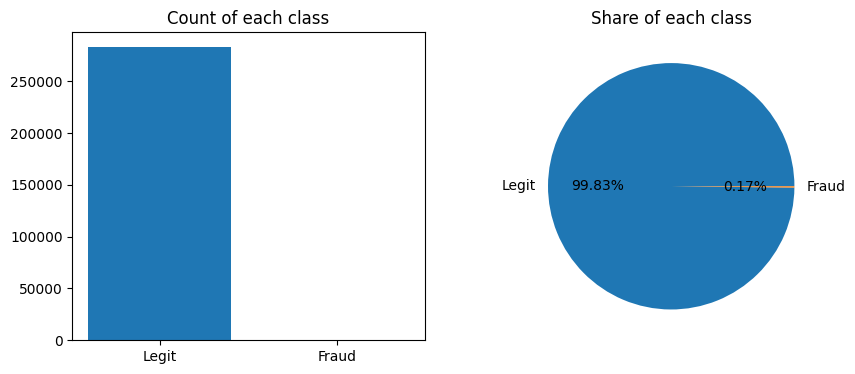

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(["Legit", "Fraud"], counts)
plt.title("Count of each class")

plt.subplot(1, 2, 2)
plt.pie(counts, labels=["Legit", "Fraud"], autopct="%.2f%%")
plt.title("Share of each class")

plt.show()

In [17]:
# accuracy of a model that always predicts legit
print("Always-legit accuracy:", round(counts[0] / len(data) * 100, 2), "%")

Always-legit accuracy: 99.83 %


**Class imbalance:** fraud is a tiny part of the data. A model that always says "legit" gets very high accuracy but catches no fraud, so accuracy is misleading. We use precision, recall and F1-score instead.

## 2. Amount: fraud vs legit

`Amount` is already scaled, so values can be negative and are not real money. That is fine for comparing the two classes.

In [18]:
data.groupby("Class")["Amount"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,0.924,3.482,-0.306,-0.227,0.000,0.771,356.962
1,473.0,1.417,3.619,-0.306,-0.292,-0.169,1.167,29.257


Median - legit: 0.0
Median - fraud: -0.169


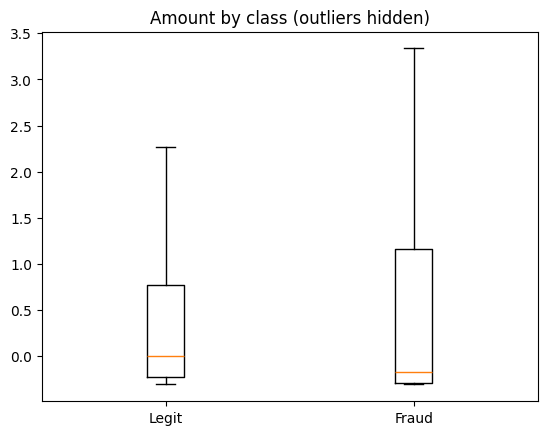

In [19]:
legit = data[data["Class"] == 0]["Amount"]
fraud = data[data["Class"] == 1]["Amount"]

print("Median - legit:", round(legit.median(), 3))
print("Median - fraud:", round(fraud.median(), 3))

plt.boxplot([legit, fraud], showfliers=False)
plt.xticks([1, 2], ["Legit", "Fraud"])
plt.title("Amount by class (outliers hidden)")
plt.show()

**Median** = middle value, more reliable than the mean when there are outliers. **Boxplot:** the box holds the middle 50% of values and the line inside is the median.

Compare the two medians above: is fraud usually smaller or larger than legit?

## 3. Correlation

**Correlation** is a number from -1 to +1 showing how two columns move together: near +1 they rise together, near -1 one rises while the other falls, near 0 there is no relation.

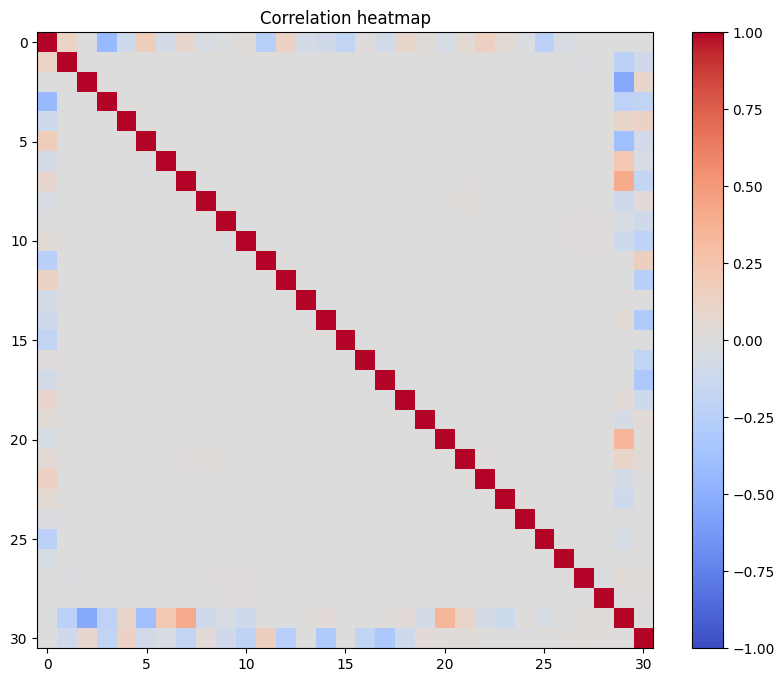

In [20]:
corr = data.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Correlation heatmap")
plt.show()

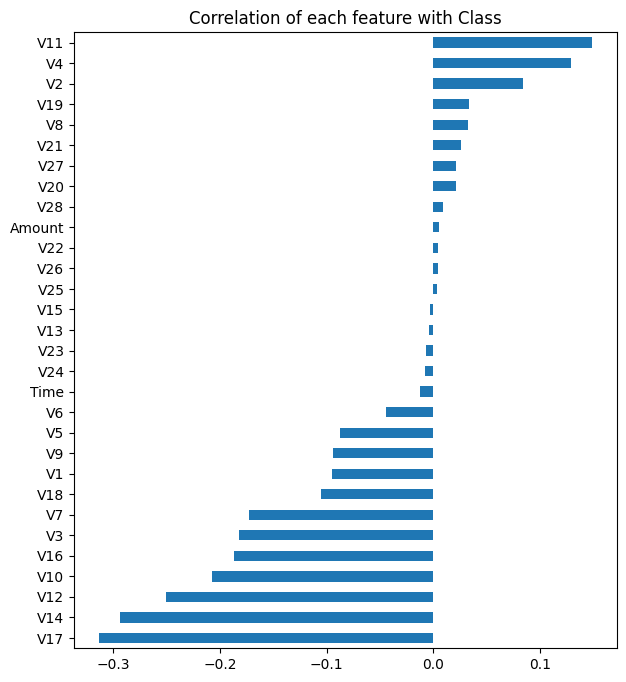

Top 6 features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


In [21]:
# correlation of every column with Class
corr_class = corr["Class"].drop("Class").sort_values()

plt.figure(figsize=(7, 8))
corr_class.plot(kind="barh")
plt.title("Correlation of each feature with Class")
plt.show()

# 6 strongest features (ignoring + or -)
top6 = corr_class.abs().sort_values(ascending=False).head(6).index.tolist()
print("Top 6 features:", top6)

The `V` columns are almost unrelated to each other (they come from PCA). Only a few of them relate clearly to `Class`, and those are the best candidates for prediction.

## 4. Top features: fraud vs legit

If the two histograms sit in different places, the feature can separate fraud from legit.

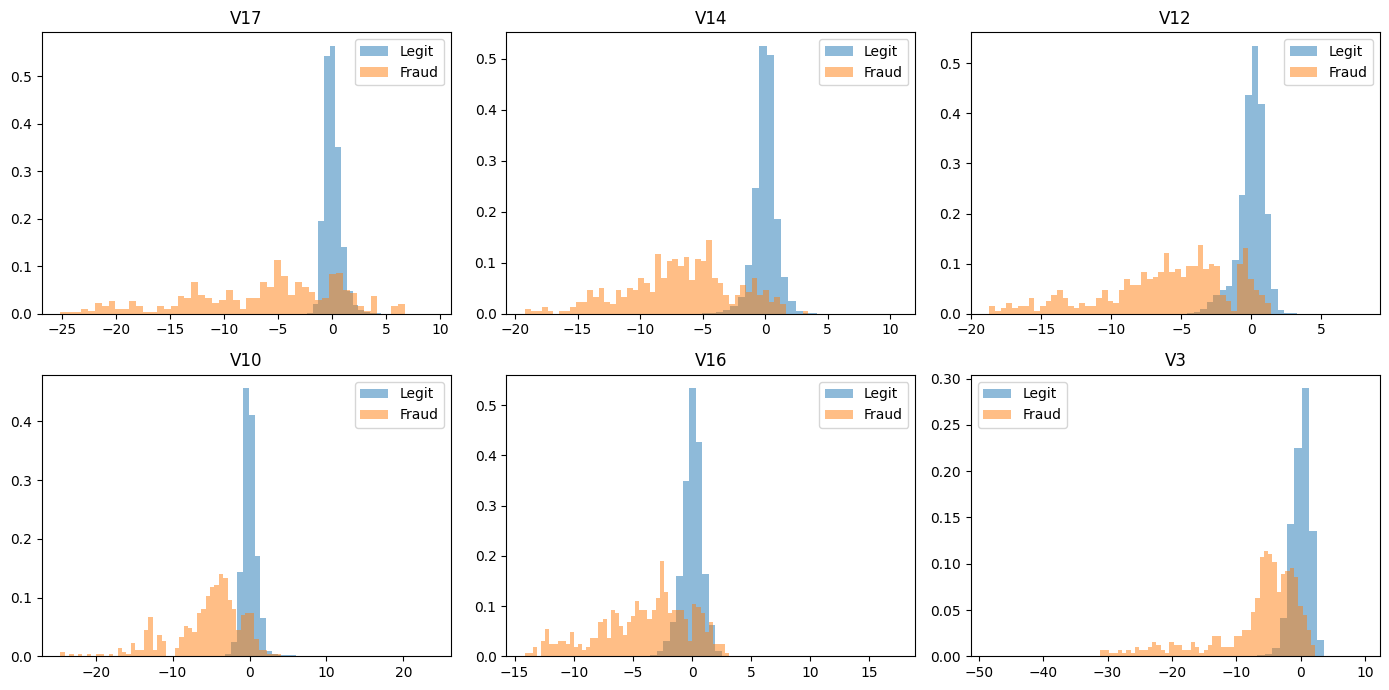

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, f in zip(axes, top6):
    ax.hist(data[data["Class"] == 0][f], bins=50, alpha=0.5, density=True, label="Legit")
    ax.hist(data[data["Class"] == 1][f], bins=50, alpha=0.5, density=True, label="Fraud")
    ax.set_title(f)
    ax.legend()

plt.tight_layout()
plt.show()

## 5. Hypothesis testing

A test checks whether a difference is real or just luck.
- **H0:** no difference. **H1:** there is a difference.
- **p-value:** chance of seeing this data if H0 were true.
- **alpha = 0.05:** if p < 0.05 we reject H0 (difference is real), otherwise we fail to reject H0.

In [23]:
alpha = 0.05

### 5.1 Is Amount normal? (Shapiro-Wilk)
H0: Amount is normal. H1: Amount is not normal. (Random sample of 5000 rows.)

In [24]:
sample = data["Amount"].sample(5000, random_state=42)
stat, p = stats.shapiro(sample)

print("p-value:", p)
if p < alpha:
    print("Reject H0: Amount is NOT normal")
else:
    print("Fail to reject H0: Amount looks normal")

p-value: 7.04314730457547e-87
Reject H0: Amount is NOT normal


Amount is not normal, so we use the **Mann-Whitney U test**, which does not need normal data.

### 5.2 Is Amount different for fraud and legit? (Mann-Whitney U)
H0: same amounts. H1: different amounts.

In [25]:
u, p = stats.mannwhitneyu(fraud, legit)

print("p-value:", p)
if p < alpha:
    print("Reject H0: fraud and legit amounts are different")
else:
    print("Fail to reject H0: no clear difference in amount")

p-value: 2.68609023836721e-05
Reject H0: fraud and legit amounts are different


### 5.3 Which features separate fraud best? (Kolmogorov-Smirnov)
A higher KS value means the two classes look more different for that feature.

In [26]:
features = [c for c in data.columns if c != "Class"]

results = []
for f in features:
    ks, p = stats.ks_2samp(data[data["Class"] == 1][f], data[data["Class"] == 0][f])
    results.append([f, ks, p])

ks_df = pd.DataFrame(results, columns=["Feature", "KS value", "p-value"])
ks_df.sort_values("KS value", ascending=False).head(10)

,Feature,KS value,p-value
14,V14,0.837728,0.000000e+00
10,V10,0.797033,2.075076e-322
12,V12,0.776641,6.308054e-301
4,V4,0.760732,3.049831e-285
11,V11,0.747380,1.003387e-272
17,V17,0.735532,4.575127e-262
3,V3,0.695176,1.520318e-228
16,V16,0.678206,1.384678e-215
7,V7,0.651649,1.731242e-196
2,V2,0.624074,4.735902e-178


The top features here should match the top features from the correlation chart.

## Summary
1. Data is highly imbalanced, so accuracy is misleading. Use precision, recall and F1.
2. Amount is not normal; fraud and legit amounts differ (Mann-Whitney).
3. A few V features carry most of the information (correlation and KS agree).